# 01 · Exploratory data analysis of the synthetic training data

**Goal (Phase 4, step 4.8):** check that the generated data behaves like real personal finances before any model sees it:
seasonality, different income patterns per user type, no gaps, sensible outliers.

> **Data honesty:** everything here is **synthetic** — 300 generated users × 36 months from
> `src/ingestion/synthetic_generator.py` (seed 42). Regenerate with `python pipelines/run_ingestion.py`.
> Macro data (ECB) is not part of this notebook; it joins the feature table in Phase 6.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# find the project root (the folder with config/) so imports and paths work from notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT))
from src.utils.helpers import load_config, resolve_path

config = load_config()
RAW = resolve_path(config["paths"]["data_raw"])
tx = pd.read_csv(RAW / config["synthetic"]["transactions_file"], parse_dates=["date"])
users = pd.read_csv(RAW / config["synthetic"]["users_file"])
calendar = pd.read_csv(RAW / config["calendar"]["file"])
tx["month"] = tx["date"].dt.to_period("M")

# one consistent look: thin lines, recessive grid, the app's colours
ARCHETYPE_ORDER = ["salaried_single", "salaried_family", "freelancer", "student"]
ARCHETYPE_COLORS = dict(zip(ARCHETYPE_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INCOME, SPENDING, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "lines.linewidth": 2,
    "font.size": 10,
})
euro = lambda v: f"€{v:,.0f}"
print(f"{len(tx):,} transactions · {tx['user_id'].nunique()} users · {tx['month'].min()} → {tx['month'].max()}")

380,911 transactions · 300 users · 2023-10 → 2026-09


## 1. Overview and completeness

In [2]:
overview = pd.DataFrame({
    "users": users["archetype"].value_counts(),
    "share": users["archetype"].value_counts(normalize=True).map("{:.0%}".format),
    "transactions": tx.groupby("archetype").size(),
}).loc[ARCHETYPE_ORDER]
overview["tx per user-month"] = (overview["transactions"] / (overview["users"] * tx["month"].nunique())).round(1)
display(overview)

per_user_months = tx.groupby("user_id")["month"].nunique()
print("Months per user: min", per_user_months.min(), "· max", per_user_months.max(),
      "→ missing user-months:", int((tx["month"].nunique() - per_user_months).sum()))
print("Missing values:", int(tx.isna().sum().sum()), "· zero amounts:", int((tx["amount"] == 0).sum()))

,users,share,transactions,tx per user-month
archetype,,,,
salaried_single,111,37%,134278,33.6
salaried_family,74,25%,97875,36.7
freelancer,76,25%,102360,37.4
student,39,13%,46398,33.0


Months per user: min 36 · max 36 → missing user-months: 0
Missing values: 0 · zero amounts: 0


## 2. Monthly income and spending by user type
Median user of each type, month by month.

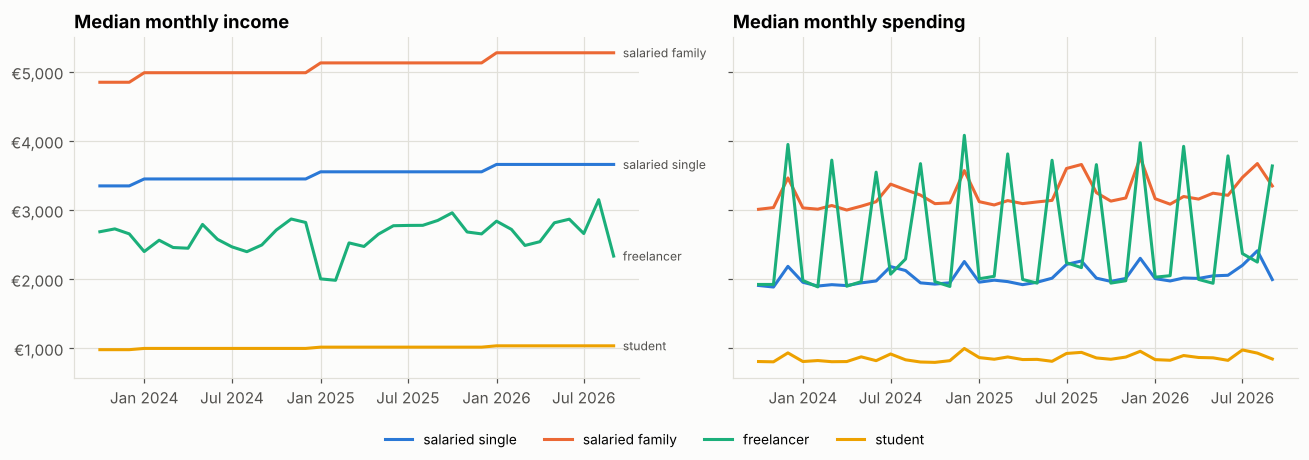

In [3]:
monthly = (tx.assign(income=tx["amount"].clip(lower=0), spending=(-tx["amount"]).clip(lower=0))
             .groupby(["archetype", "user_id", "month"])[["income", "spending"]].sum().reset_index())
median = monthly.groupby(["archetype", "month"])[["income", "spending"]].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, column, title in zip(axes, ["income", "spending"], ["Median monthly income", "Median monthly spending"]):
    for archetype in ARCHETYPE_ORDER:
        part = median[median["archetype"] == archetype]
        x = part["month"].dt.to_timestamp()
        ax.plot(x, part[column], color=ARCHETYPE_COLORS[archetype], label=archetype.replace("_", " "))
        if column == "income":
            ax.annotate(archetype.replace("_", " "), (x.iloc[-1], part[column].iloc[-1]), xytext=(6, 0),
                        textcoords="offset points", va="center", color=INK, fontsize=8)
    ax.set_title(title, loc="left")
    ax.yaxis.set_major_formatter(lambda v, _: euro(v))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 3. Income stability
Coefficient of variation (std ÷ mean) of each user's monthly income. Low = predictable.

,mean,50%,min,max
archetype,,,,
salaried_single,0.028,0.028,0.028,0.028
salaried_family,0.026,0.026,0.026,0.027
freelancer,0.628,0.617,0.369,1.112
student,0.017,0.017,0.014,0.020


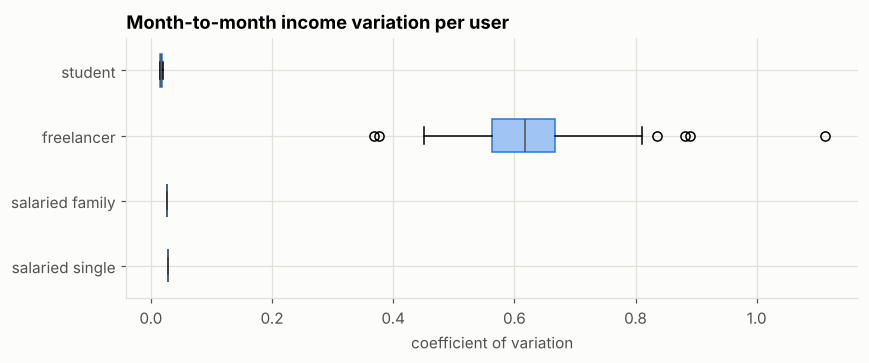

In [4]:
cv = (monthly.groupby(["archetype", "user_id"])["income"]
        .agg(lambda s: s.std() / s.mean()).rename("income_cv").reset_index())
display(cv.groupby("archetype")["income_cv"].describe()[["mean", "50%", "min", "max"]].loc[ARCHETYPE_ORDER].round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
data = [cv.loc[cv["archetype"] == a, "income_cv"] for a in ARCHETYPE_ORDER]
box = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.5, medianprops={"color": INK})
for patch in box["boxes"]:
    patch.set(facecolor="#9ec5f4", edgecolor="#2a78d6")
ax.set_yticks(range(1, 5), [a.replace("_", " ") for a in ARCHETYPE_ORDER])
ax.set_title("Month-to-month income variation per user", loc="left")
ax.set_xlabel("coefficient of variation")
fig.tight_layout(); plt.show()

## 4. Seasonality by category
Spending per calendar month relative to that category's average month (1.0 = normal).

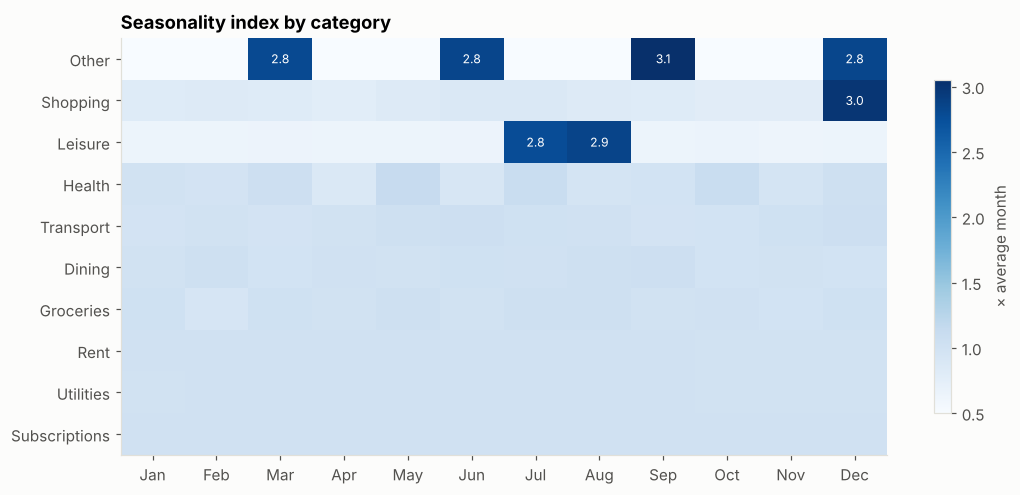

Peaks (≥ 1.3× average):
category  cal_month
Other     3            2.80
          6            2.84
          9            3.05
          12           2.83
Shopping  12           2.99
Leisure   7            2.77
          8            2.85


In [5]:
spend = tx[tx["amount"] < 0].assign(spending=lambda d: -d["amount"], cal_month=lambda d: d["date"].dt.month)
by_month = spend.groupby(["category", "cal_month"])["spending"].sum().unstack()
seasonal_index = by_month.div(by_month.mean(axis=1), axis=0)
seasonal_index = seasonal_index.loc[seasonal_index.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(seasonal_index.values, cmap="Blues", aspect="auto", vmin=0.5, vmax=max(2.0, seasonal_index.values.max()))
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(seasonal_index)), seasonal_index.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(seasonal_index.values):
    if v >= 1.3:
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white")
fig.colorbar(im, ax=ax, label="× average month", shrink=0.8)
ax.set_title("Seasonality index by category", loc="left")
fig.tight_layout(); plt.show()
print("Peaks (≥ 1.3× average):")
peaks = seasonal_index.stack()
print(peaks[peaks >= 1.3].round(2).to_string())

## 5. Spending mix by user type
Share of each category in total spending.

In [6]:
mix = spend.groupby(["archetype", "category"])["spending"].sum().unstack(fill_value=0)
mix = mix.div(mix.sum(axis=1), axis=0).loc[ARCHETYPE_ORDER]
mix = mix[mix.mean().sort_values(ascending=False).index]
display((mix * 100).round(1).astype(str) + "%")

monthly_spend = monthly.groupby("archetype")["spending"].mean().loc[ARCHETYPE_ORDER]
print("Average monthly spending:", {k: euro(v) for k, v in monthly_spend.items()})

category,Rent,Groceries,Transport,Shopping,Leisure,Utilities,Other,Dining,Subscriptions,Health
archetype,,,,,,,,,,
salaried_single,45.0%,12.1%,10.0%,7.1%,7.4%,6.1%,0.4%,7.3%,2.9%,1.8%
salaried_family,44.9%,19.7%,8.6%,5.8%,6.4%,6.6%,0.8%,3.5%,2.2%,1.5%
freelancer,33.1%,9.4%,9.1%,5.6%,5.4%,5.6%,21.3%,5.6%,3.5%,1.3%
student,36.8%,13.4%,15.4%,9.6%,6.4%,5.4%,0.4%,6.4%,2.2%,4.0%


Average monthly spending: {'salaried_single': '€2,078', 'salaried_family': '€3,283', 'freelancer': '€2,558', 'student': '€884'}


## 6. Big costs: planned vs. unplanned
Large expenses come in two kinds. **Planned** ones repeat on a calendar (freelancer tax prepayments every quarter,
yearly insurance, summer trips) and can be learned. **Unplanned shocks** (car repair, dentist, broken washing machine)
happen at random and are what makes a single month hard to predict.

,payments,total,typical
kind,,,
planned / seasonal,2541,"€2,298,852",€638
unplanned shock,352,"€258,192",€658


Unplanned shocks: 461 payments in 461 of 10,800 user-months (4.3%); median €511, largest €1,596


,user_id,archetype,date,description,amount,category
177396,user_139,freelancer,2026-08-28,MediaMarkt Laptop,-1595.56,Shopping
208716,user_164,salaried_single,2026-05-13,MediaMarkt Laptop,-1582.68,Shopping
331454,user_261,salaried_single,2026-06-18,MediaMarkt Laptop,-1558.20,Shopping
260078,user_205,salaried_single,2026-05-12,MediaMarkt Laptop,-1557.11,Shopping
216098,user_170,student,2025-06-12,MediaMarkt Laptop,-1525.31,Shopping
134254,user_105,freelancer,2026-02-03,MediaMarkt Laptop,-1517.09,Shopping
380375,user_300,freelancer,2025-07-05,MediaMarkt Laptop,-1515.85,Shopping
52606,user_041,salaried_family,2026-08-23,MediaMarkt Laptop,-1494.55,Shopping


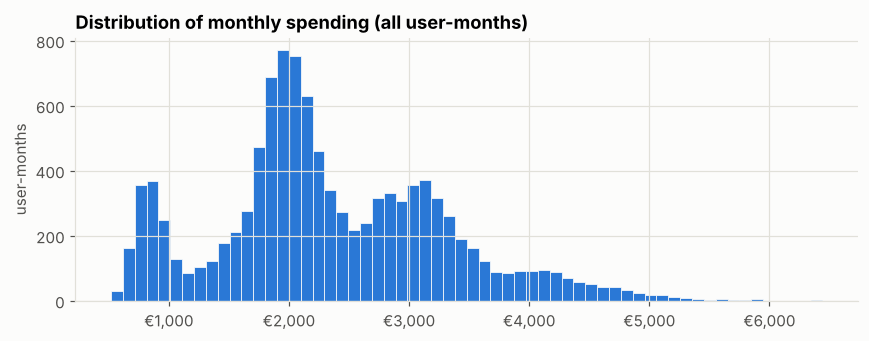

In [7]:
from src.ingestion.synthetic_generator import SHOCKS

shock_names = {name for name, *_ in SHOCKS}
expenses = tx[tx["amount"] < 0]
big = expenses[(expenses["amount"] <= -300) & (expenses["category"] != "Rent")]
kind = np.where(big["description"].isin(shock_names), "unplanned shock", "planned / seasonal")
summary = big.assign(kind=kind).groupby("kind").agg(
    payments=("amount", "size"), total=("amount", lambda a: euro(-a.sum())), typical=("amount", lambda a: euro(-a.median())))
display(summary)

shocks = expenses[expenses["description"].isin(shock_names)]
shock_months = shocks.groupby(["user_id", "month"]).ngroups
print(f"Unplanned shocks: {len(shocks):,} payments in {shock_months:,} of {len(monthly):,} user-months "
      f"({shock_months / len(monthly):.1%}); median {euro(-shocks['amount'].median())}, largest {euro(-shocks['amount'].min())}")
display(shocks.nsmallest(8, "amount")[["user_id", "archetype", "date", "description", "amount", "category"]])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(monthly["spending"], bins=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.5)
ax.set_title("Distribution of monthly spending (all user-months)", loc="left")
ax.xaxis.set_major_formatter(lambda v, _: euro(v)); ax.set_ylabel("user-months")
fig.tight_layout(); plt.show()

## 7. Calendar
Holidays per month (Germany) next to total spending of all users.

In [8]:
calendar["month"] = pd.PeriodIndex(calendar["month"], freq="M")
total = monthly.groupby("month")["spending"].sum().rename("total_spending").reset_index()
cal = calendar.merge(total, on="month")
display(cal[cal["holidays"] > 0][["month", "holidays", "working_days", "total_spending"]]
        .assign(total_spending=lambda d: d["total_spending"].map(euro)))
print("Correlation holidays ↔ total spending:", round(cal["holidays"].corr(cal["total_spending"]), 2))
print("December (2 holidays) is a spending peak, but May 2024/2026 (3 holidays) are ordinary months:",
      "the holiday count alone says little; month-of-year carries the seasonal signal.")

,month,holidays,working_days,total_spending
0,2023-10,1,21,"€618,038"
2,2023-12,2,19,"€836,273"
3,2024-01,1,22,"€620,832"
5,2024-03,1,20,"€745,672"
6,2024-04,1,21,"€618,049"
7,2024-05,3,20,"€633,236"
12,2024-10,1,22,"€626,621"
14,2024-12,2,20,"€857,957"
15,2025-01,1,22,"€640,041"
18,2025-04,2,20,"€630,056"


Correlation holidays ↔ total spending: -0.08
December (2 holidays) is a spending peak, but May 2024/2026 (3 holidays) are ordinary months: the holiday count alone says little; month-of-year carries the seasonal signal.


## 8. Findings and what they mean for the models

| # | Finding | Evidence | Consequence for Phases 5–7 |
|---|---|---|---|
| 1 | **The data is complete.** | 380,911 transactions, every one of 300 users has all 36 months, no missing values or zero amounts. | No gap-filling needed for the synthetic data; the gap check in `aggregate_monthly` matters for *real* user uploads. |
| 2 | **Salaried and student income is almost flat; freelancer income is not.** | Income variation (CV) ≈ 0.02–0.03 for salaried users and students vs. **0.63** for freelancers (range 0.37–1.11). Salaries step up each January. | A "same as last month" baseline will be very hard to beat for salaried income. Model effort should go to **freelancer income** and **variable spending**, as the blueprint expects. Results must be reported per user type. |
| 3 | **Spending has strong, regular seasonality.** | Shopping 3.0× normal in December (gifts); Leisure 2.8–2.9× in July/August (trips); "Other" ~2.8–3.1× in March/June/September/December. | Month-of-year (sin/cos) and the 12-month lag are essential features. |
| 4 | **Freelancer spending spikes every quarter.** | Quarterly income-tax prepayments make up **21%** of freelancer spending ("Other"). | Predictable from the calendar: forecast per category, so the tax category carries the spike instead of confusing the total. |
| 5 | **Rent dominates every budget.** | Rent is 33–45% of spending; groceries are the next biggest for families (19.7%). | Fixed costs are easy; the forecasting error will come from groceries, dining, shopping and leisure. |
| 6 | **Unplanned shocks are rare but large.** | 4.3% of user-months contain a shock (car repair, dentist, laptop…), median €511, up to ~€1,600. Planned big costs (tax, insurance, trips) are far more common. | Point forecasts cannot see shocks coming → the **10th–90th percentile range** (quantile models) is what keeps the forecast honest. |
| 7 | **Holiday counts alone say little.** | Correlation between holidays per month and total spending: −0.08. | Keep holidays as a feature, but expect low importance; month-of-year carries the seasonal signal. |
| 8 | **Four clearly different user types.** | Average monthly spending: students €884, salaried single €2,078, freelancers €2,558, families €3,283 — the multi-peak histogram above. | Archetype-level differences justify a **global model** with per-user lag features rather than one model per user. |

**Done-when check for step 4.8:** clear seasonality ✓ · different income patterns per archetype ✓.